# Statystyki serwisu z pliku LOG

- Michał Mizia
- Jakub Kwaśniak

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

LOG_PATH = "../data/predictions.log"
MULTIPLIER = 2  # must match app/main.py

## Załadowanie Loga

In [9]:
rows = []
with open(LOG_PATH, "r", encoding="utf-8") as f:
    for line in f:
        rows.append(json.loads(line))

df = pd.json_normalize(rows)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["input.date"] = pd.to_datetime(df["input.date"])
df.rename(
    columns={
        "input.price": "actual_price",
        "input.neighbourhood_group_cleansed": "neighbourhood",
        "input.property_type": "property_type",
        "input.room_type": "room_type",
    },
    inplace=True,
)
print(f"{len(df)} zapytan, {df['timestamp'].min()} -> {df['timestamp'].max()}")
df.head()

100 zapytan, 2026-06-02 07:19:39.715563+00:00 -> 2026-06-02 07:23:01.292036+00:00


,timestamp,request_id,model,is_overpriced,predicted_price,price_ratio,input.date,actual_price,neighbourhood,property_type,room_type,input.accommodates,input.bathrooms,input.bedrooms,input.beds
0,2026-06-02 07:19:39.715563+00:00,9e2740e6-51cb-4241-a01a-4d1ceaacc2e5,baseline,0,1392.127160,0.553110,2024-12-26,770.00,Pankow,Entire home,Entire home/apt,7,NaN,3.0,NaN
1,2026-06-02 07:19:41.755111+00:00,52e4b14c-9e1a-4dee-8472-825eefcfccb5,baseline,0,206.898839,1.044375,2025-06-21,216.08,Tempelhof - Schöneberg,Private room in rental unit,Private room,2,NaN,NaN,NaN
2,2026-06-02 07:19:43.790757+00:00,2211e4d3-a946-4cb9-b434-f5f5dbcabd7b,baseline,0,650.663082,0.824943,2025-07-04,536.76,Mitte,Entire rental unit,Entire home/apt,6,1.0,2.0,6.0
3,2026-06-02 07:19:45.821690+00:00,ac8b81ff-736f-4ea4-8efc-23a7afdcf0de,advanced,0,636.211238,1.023528,2025-05-12,651.18,Mitte,Entire rental unit,Entire home/apt,4,1.5,2.0,2.0
4,2026-06-02 07:19:47.861145+00:00,8a2da800-3e94-4bf9-9d68-e08b31900eaf,baseline,0,338.048319,1.052749,2025-11-19,355.88,Friedrichshain-Kreuzberg,Entire condo,Entire home/apt,4,1.5,2.0,2.0


## Statystyki modeli

In [3]:
traffic = df.groupby("model").agg(
    requests=("request_id", "count"),
    share=("request_id", lambda s: len(s) / len(df)),
    flag_rate=("is_overpriced", "mean"),
    median_actual=("actual_price", "median"),
    median_predicted=("predicted_price", "median"),
    median_ratio=("price_ratio", "median"),
)
traffic

,requests,share,flag_rate,median_actual,median_predicted,median_ratio
model,,,,,,
advanced,45,0.45,0.022222,262.06,326.277530,0.837896
baseline,55,0.55,0.090909,362.35,398.323633,0.879096


## Przewidywana vs Wywoławcza cena dla obu modeli

Linia cała y=x to równa cena przewidywana i wywoławcza. Kropki poniżej lini przerywanej mają cenę wywoławczą 2x większą niż cena przewidywana i są oznaczone jako podejrzane o nieuczciwość

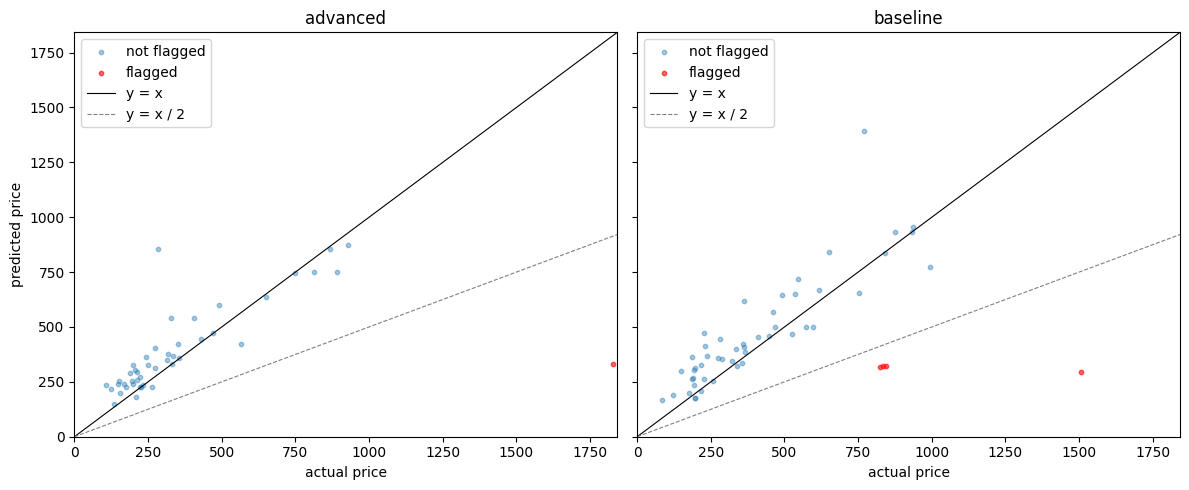

In [4]:
arms = sorted(df["model"].unique())
fig, axes = plt.subplots(1, len(arms), figsize=(6 * len(arms), 5), sharex=True, sharey=True)
if len(arms) == 1:
    axes = [axes]

lim_max = max(df["actual_price"].quantile(0.99), df["predicted_price"].quantile(0.99))
x_line = np.linspace(0, lim_max, 100)

for ax, arm in zip(axes, arms):
    sub = df[df["model"] == arm]
    flagged = sub[sub["is_overpriced"] == 1]
    normal = sub[sub["is_overpriced"] == 0]
    ax.scatter(normal["actual_price"], normal["predicted_price"], s=10, alpha=0.4, label="not flagged")
    ax.scatter(flagged["actual_price"], flagged["predicted_price"], s=10, alpha=0.6, color="red", label="flagged")
    ax.plot(x_line, x_line, color="black", linewidth=0.8, label="y = x")
    ax.plot(x_line, x_line / MULTIPLIER, color="grey", linewidth=0.8, linestyle="--", label=f"y = x / {MULTIPLIER}")
    ax.set_title(arm)
    ax.set_xlabel("actual price")
    ax.set_xlim(0, lim_max)
    ax.set_ylim(0, lim_max)
    ax.legend(loc="upper left")
axes[0].set_ylabel("predicted price")
plt.tight_layout()
plt.show()

## Dystrybucja rozkładu cena wywoławcza / cena przewidywana

Widzimy że rozkład jest normalny, z dodatkowym ogonem po prawej stronie, co mocno pokazuje istnienie sztucznego zawyżania cen.

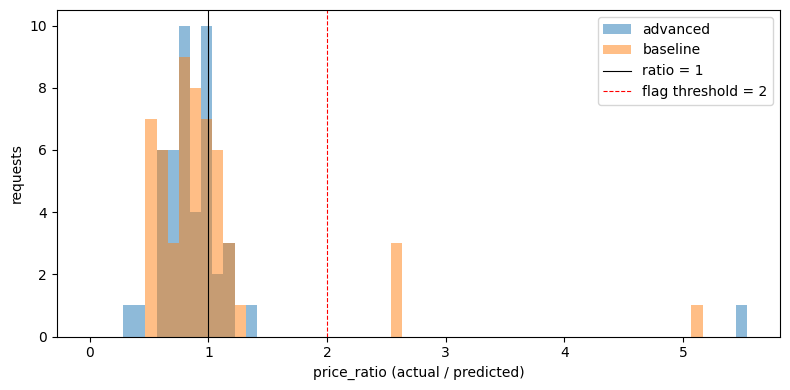

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, df["price_ratio"].quantile(0.99), 60)
for arm in arms:
    ax.hist(df.loc[df["model"] == arm, "price_ratio"], bins=bins, alpha=0.5, label=arm)
ax.axvline(1.0, color="black", linewidth=0.8, label="ratio = 1")
ax.axvline(MULTIPLIER, color="red", linewidth=0.8, linestyle="--", label=f"flag threshold = {MULTIPLIER}")
ax.set_xlabel("price_ratio (actual / predicted)")
ax.set_ylabel("requests")
ax.legend()
plt.tight_layout()
plt.show()

## Rozkład na neighbourhood

In [6]:
TOP_N = 8
top_neighborhoods = df["neighbourhood"].value_counts().head(TOP_N).index

nbh = (
    df[df["neighbourhood"].isin(top_neighborhoods)]
    .groupby(["neighbourhood", "model"]).agg(
        n=("request_id", "count"),
        median_actual=("actual_price", "median"),
        median_predicted=("predicted_price", "median"),
        mean_ratio=("price_ratio", "mean"),
        flag_rate=("is_overpriced", "mean"),
    )
    .round(2)
)
nbh

n  median_actual  median_predicted  \
neighbourhood            model                                           
Charlottenburg-Wilm.     advanced   9         221.18            289.39   
                         baseline   1         192.16            303.18   
Friedrichshain-Kreuzberg advanced  14         227.16            304.69   
                         baseline  14         364.51            352.53   
Lichtenberg              advanced   1         168.24            240.08   
                         baseline   1          85.29            167.07   
Mitte                    advanced   7         651.18            636.21   
                         baseline  12         585.64            499.81   
Neukölln                 advanced   5         231.37            270.19   
                         baseline   6         393.04            465.64   
Pankow                   advanced   7         317.35            375.81   
                         baseline  16         269.41            389.77   
Spandau                  baseline   2         196.18            176.48   
Tempelhof - Schöneberg   advanced   1         213.24            256.73   
                         baseline   2         204.12            220.77   

                                   mean_ratio  flag_rate  
neighbourhood            model                            
Charlottenburg-Wilm.     advanced        0.84       0.00  
                         baseline        0.63       0.00  
Friedrichshain-Kreuzberg advanced        0.84       0.00  
                         baseline        1.29       0.14  
Lichtenberg              advanced        0.70       0.00  
                         baseline        0.51       0.00  
Mitte                    advanced        0.97       0.00  
                         baseline        1.21       0.17  
Neukölln                 advanced        0.86       0.00  
                         baseline        0.84       0.00  
Pankow                   advanced        1.42       0.14  
                         baseline        1.09       0.06  
Spandau                  baseline        1.11       0.00  
Tempelhof - Schöneberg   advanced        0.83       0.00  
                         baseline        0.93       0.00

## Rozkład na typ pokoju

In [7]:
room = (
    df.groupby(["room_type", "model"]).agg(
        n=("request_id", "count"),
        median_actual=("actual_price", "median"),
        median_predicted=("predicted_price", "median"),
        mean_ratio=("price_ratio", "mean"),
        flag_rate=("is_overpriced", "mean"),
    )
    .round(2)
)
room

n  median_actual  median_predicted  mean_ratio  \
room_type       model                                                       
Entire home/apt advanced  30         322.80            389.10        0.86   
                baseline  44         465.54            454.53        1.18   
Private room    advanced  15         213.24            240.08        1.12   
                baseline  11         192.16            206.90        0.85   

                          flag_rate  
room_type       model                
Entire home/apt advanced       0.00  
                baseline       0.11  
Private room    advanced       0.07  
                baseline       0.00